# 🎬 MovieLens Tavsiye Sistemi
## SVD++ ve NMF Algoritmaları ile Karşılaştırmalı Analiz
**Veri Seti:** MovieLens 25M | **Algoritma:** SVD++, NMF | **Metrikler:** Precision@K, Recall@K, NDCG@K, MAP

## 📦 Bölüm 0 — Kütüphane Kurulumu

In [2]:
import subprocess, sys
packages = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-surprise']
for pkg in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])
print('✅ Tüm kütüphaneler hazır!')

✅ Tüm kütüphaneler hazır!


## 📚 Bölüm 1 — Import'lar

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import math, time, warnings, random
warnings.filterwarnings('ignore')

from surprise import SVDpp, NMF, Dataset, Reader
from collections import defaultdict

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
print('✅ Importlar tamamlandi!')

✅ Importlar tamamlandi!


## 📂 Bölüm 2 — Veri Yükleme

In [4]:
RATING_PATH = r'C:\Users\Huseyin\Desktop\Movie_Lens\data\rating.csv'
MOVIE_PATH  = r'C:\Users\Huseyin\Desktop\Movie_Lens\data\movie.csv'

print('Veriler yukleniyor...')
start = time.time()
ratings = pd.read_csv(RATING_PATH)
movies  = pd.read_csv(MOVIE_PATH)
print(f'✅ Yukleme suresi : {time.time()-start:.1f}s')
print(f'   Rating sayisi  : {len(ratings):,}')
print(f'   Film sayisi    : {len(movies):,}')
print(f'\nRating sutunlari : {list(ratings.columns)}')
print(f'Movie sutunlari  : {list(movies.columns)}')

Veriler yukleniyor...
✅ Yukleme suresi : 14.0s
   Rating sayisi  : 20,000,263
   Film sayisi    : 27,278

Rating sutunlari : ['userId', 'movieId', 'rating', 'timestamp']
Movie sutunlari  : ['movieId', 'title', 'genres']


## 🔍 Bölüm 3 — Veri Keşfi (EDA)

In [5]:
print('='*50)
print('RATING VERISI — ILK 5 SATIR')
print('='*50)
display(ratings.head())

print('\n' + '='*50)
print('TEMEL ISTATISTIKLER')
print('='*50)
display(ratings.describe())

print('\n' + '='*50)
print('GENEL BILGILER')
print('='*50)
print(f'Toplam rating sayisi  : {len(ratings):,}')
print(f'Benzersiz kullanici   : {ratings["userId"].nunique():,}')
print(f'Benzersiz film        : {ratings["movieId"].nunique():,}')
print(f'Rating araligi        : {ratings["rating"].min()} - {ratings["rating"].max()}')
print(f'Ortalama rating       : {ratings["rating"].mean():.2f}')
print(f'Eksik deger var mi?   : {ratings.isnull().sum().sum()}')

RATING VERISI — ILK 5 SATIR


,userId,movieId,rating,timestamp
0,1,2,3.5,2005-04-02 23:53:47
1,1,29,3.5,2005-04-02 23:31:16
2,1,32,3.5,2005-04-02 23:33:39
3,1,47,3.5,2005-04-02 23:32:07
4,1,50,3.5,2005-04-02 23:29:40



TEMEL ISTATISTIKLER


,userId,movieId,rating
count,2.000026e+07,2.000026e+07,2.000026e+07
mean,6.904587e+04,9.041567e+03,3.525529e+00
std,4.003863e+04,1.978948e+04,1.051989e+00
min,1.000000e+00,1.000000e+00,5.000000e-01
25%,3.439500e+04,9.020000e+02,3.000000e+00
50%,6.914100e+04,2.167000e+03,3.500000e+00
75%,1.036370e+05,4.770000e+03,4.000000e+00
max,1.384930e+05,1.312620e+05,5.000000e+00



GENEL BILGILER
Toplam rating sayisi  : 20,000,263
Benzersiz kullanici   : 138,493
Benzersiz film        : 26,744
Rating araligi        : 0.5 - 5.0
Ortalama rating       : 3.53
Eksik deger var mi?   : 0


In [6]:
# Unique rating degerleri
print('='*50)
print('UNIQUE RATING DEGERLERI')
print('='*50)
unique_ratings = sorted(ratings['rating'].unique())
print(f'Unique rating degerleri : {unique_ratings}')
print(f'Toplam unique rating    : {len(unique_ratings)}')
print('\nHer rating degerinin frekansi:')
rating_freq = ratings['rating'].value_counts().sort_index()
for r, count in rating_freq.items():
    print(f'  {r} yildiz : {count:>10,} rating ({count/len(ratings)*100:.1f}%)')

UNIQUE RATING DEGERLERI
Unique rating degerleri : [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
Toplam unique rating    : 10

Her rating degerinin frekansi:
  0.5 yildiz :    239,125 rating (1.2%)
  1.0 yildiz :    680,732 rating (3.4%)
  1.5 yildiz :    279,252 rating (1.4%)
  2.0 yildiz :  1,430,997 rating (7.2%)
  2.5 yildiz :    883,398 rating (4.4%)
  3.0 yildiz :  4,291,193 rating (21.5%)
  3.5 yildiz :  2,200,156 rating (11.0%)
  4.0 yildiz :  5,561,926 rating (27.8%)
  4.5 yildiz :  1,534,824 rating (7.7%)
  5.0 yildiz :  2,898,660 rating (14.5%)


In [7]:
print('='*50)
print('KULLANICI BASINA ISTATISTIKLER')
print('='*50)
user_stats = ratings.groupby('userId')['rating'].agg(['count','mean'])
user_stats.columns = ['rating_sayisi', 'ort_rating']
display(user_stats.describe().round(2))

aktif_kullanici = (user_stats['rating_sayisi'] > 20).sum()
print(f'\n20den fazla rating veren kullanici sayisi: {aktif_kullanici:,}')
print(f'Tum kullanicilar icindeki orani          : %{aktif_kullanici/len(user_stats)*100:.1f}')

print('\n' + '='*50)
print('FILM BASINA ISTATISTIKLER')
print('='*50)
movie_stats = ratings.groupby('movieId')['rating'].agg(['count','mean'])
movie_stats.columns = ['rating_sayisi', 'ort_rating']
display(movie_stats.describe().round(2))

print('\n' + '='*50)
print('EN COK PUANLANAN 10 FILM')
print('='*50)
top_movies = movie_stats.nlargest(10, 'rating_sayisi').reset_index()
top_movies = top_movies.merge(movies[['movieId','title']], on='movieId')
display(top_movies[['title','rating_sayisi','ort_rating']])

KULLANICI BASINA ISTATISTIKLER


,rating_sayisi,ort_rating
count,138493.00,138493.00
mean,144.41,3.63
std,230.27,0.44
min,20.00,0.50
25%,35.00,3.37
50%,68.00,3.65
75%,155.00,3.92
max,9254.00,5.00



20den fazla rating veren kullanici sayisi: 134,008
Tum kullanicilar icindeki orani          : %96.8

FILM BASINA ISTATISTIKLER


,rating_sayisi,ort_rating
count,26744.00,26744.00
mean,747.84,3.13
std,3085.82,0.66
min,1.00,0.50
25%,3.00,2.80
50%,18.00,3.24
75%,205.00,3.57
max,67310.00,5.00



EN COK PUANLANAN 10 FILM


,title,rating_sayisi,ort_rating
0,Pulp Fiction (1994),67310,4.174231
1,Forrest Gump (1994),66172,4.029000
2,"Shawshank Redemption, The (1994)",63366,4.446990
3,"Silence of the Lambs, The (1991)",63299,4.177057
4,Jurassic Park (1993),59715,3.664741
5,Star Wars: Episode IV - A New Hope (1977),54502,4.190672
6,Braveheart (1995),53769,4.042534
7,Terminator 2: Judgment Day (1991),52244,3.931954
8,"Matrix, The (1999)",51334,4.187186
9,Schindler's List (1993),50054,4.310175


## 📊 Bölüm 4 — Veri Görselleştirme

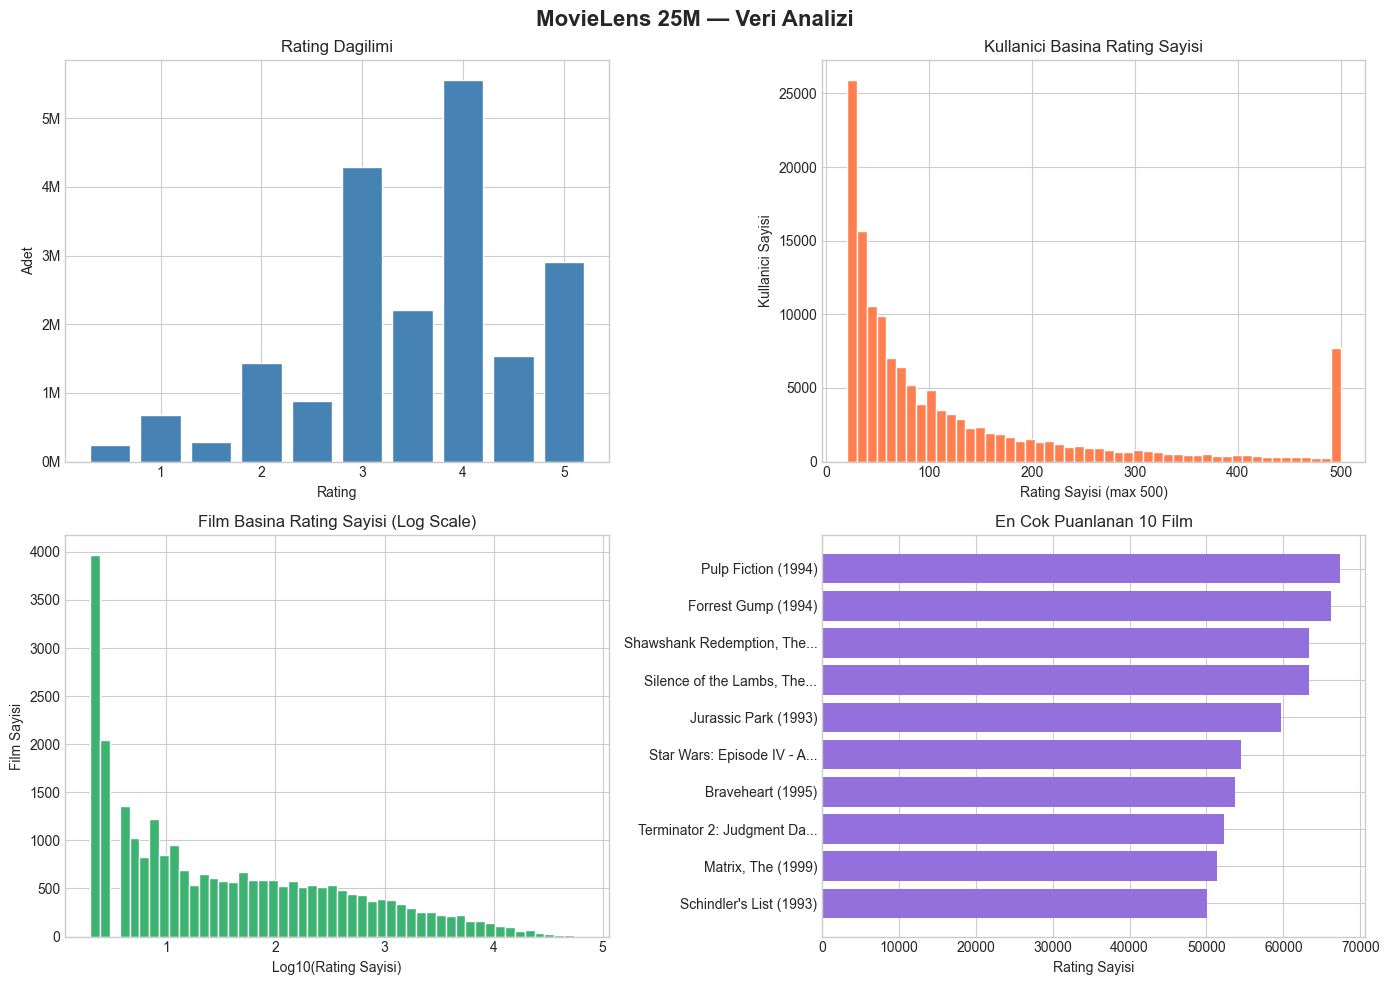

✅ Grafik kaydedildi!


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('MovieLens 25M — Veri Analizi', fontsize=16, fontweight='bold')

rating_counts = ratings['rating'].value_counts().sort_index()
axes[0,0].bar(rating_counts.index, rating_counts.values, color='steelblue', edgecolor='white', width=0.4)
axes[0,0].set_title('Rating Dagilimi')
axes[0,0].set_xlabel('Rating')
axes[0,0].set_ylabel('Adet')
axes[0,0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))

user_rating_counts = ratings.groupby('userId')['rating'].count()
axes[0,1].hist(user_rating_counts.clip(upper=500), bins=50, color='coral', edgecolor='white')
axes[0,1].set_title('Kullanici Basina Rating Sayisi')
axes[0,1].set_xlabel('Rating Sayisi (max 500)')
axes[0,1].set_ylabel('Kullanici Sayisi')

movie_rating_counts = ratings.groupby('movieId')['rating'].count()
axes[1,0].hist(np.log10(movie_rating_counts + 1), bins=50, color='mediumseagreen', edgecolor='white')
axes[1,0].set_title('Film Basina Rating Sayisi (Log Scale)')
axes[1,0].set_xlabel('Log10(Rating Sayisi)')
axes[1,0].set_ylabel('Film Sayisi')

short_titles = [t[:25]+'...' if len(t)>25 else t for t in top_movies['title']]
axes[1,1].barh(short_titles[::-1], top_movies['rating_sayisi'][::-1], color='mediumpurple')
axes[1,1].set_title('En Cok Puanlanan 10 Film')
axes[1,1].set_xlabel('Rating Sayisi')

plt.tight_layout()
plt.savefig(r'C:\Users\Huseyin\Desktop\Movie_Lens\veri_analizi.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Grafik kaydedildi!')

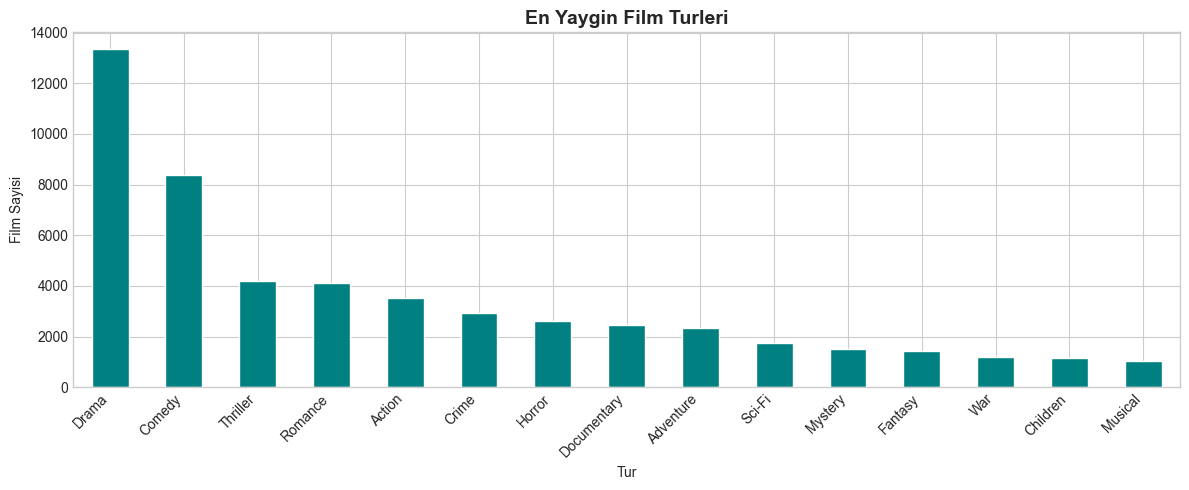

In [9]:
genre_counts = movies['genres'].str.split('|').explode().value_counts().head(15)
plt.figure(figsize=(12, 5))
genre_counts.plot(kind='bar', color='teal', edgecolor='white')
plt.title('En Yaygin Film Turleri', fontsize=14, fontweight='bold')
plt.xlabel('Tur')
plt.ylabel('Film Sayisi')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 🧮 Bölüm 5 — Algoritmaların Çalışma Mantığı (Küçük Örnekler)

In [10]:
print('='*60)
print('ORNEK: KULLANICI-FILM MATRISI')
print('='*60)
ornek_data = {
    'Film A': [5.0,   3.0,   np.nan, 1.0,   np.nan],
    'Film B': [3.0,   np.nan, 4.0,   np.nan, 2.0  ],
    'Film C': [np.nan, 5.0,   2.0,   3.0,   np.nan],
    'Film D': [4.0,   np.nan, np.nan, 5.0,   3.0  ],
    'Film E': [np.nan, 4.0,   5.0,   np.nan, 1.0  ]
}
ornek_df = pd.DataFrame(ornek_data, index=['Ali','Ayse','Mehmet','Zeynep','Can'])
print('\nKullanici-Film Rating Matrisi (NaN = izlenmedi):')
display(ornek_df)
print('\n=> Tavsiye sistemi bos hucreleri doldurmaya calisir.')

ORNEK: KULLANICI-FILM MATRISI

Kullanici-Film Rating Matrisi (NaN = izlenmedi):


,Film A,Film B,Film C,Film D,Film E
Ali,5.0,3.0,NaN,4.0,NaN
Ayse,3.0,NaN,5.0,NaN,4.0
Mehmet,NaN,4.0,2.0,NaN,5.0
Zeynep,1.0,NaN,3.0,5.0,NaN
Can,NaN,2.0,NaN,3.0,1.0



=> Tavsiye sistemi bos hucreleri doldurmaya calisir.


In [11]:
print('='*60)
print('SVD++ NASIL CALISIR?')
print('='*60)
print('''
SVD++ Matrix Factorization yontemidir.

1. TEMEL FIKIR:
   R (138K x 10K) = P (138K x k) x Q (k x 10K)
   P = Kullanici ozellikleri
   Q = Film ozellikleri
   k = Gizli faktor sayisi (50)

2. MATEMATIKSEL FORMUL:
   r_ui = mu + b_u + b_i + q_i^T(p_u + implicit)
   mu   = global ortalama
   b_u  = kullanici bias
   b_i  = film bias

3. SVD++ FARKI:
   Normal SVD sadece rating lere bakar.
   SVD++ hangi filmler izlenmis bilgisini de kullanir.
''')

p_ali       = np.array([0.9, 0.2])
q_inception = np.array([0.8, 0.3])
q_titanic   = np.array([0.1, 0.9])
mu, b_ali, b_inception, b_titanic = 3.5, 0.2, 0.3, -0.1

pred_inception = mu + b_ali + b_inception + np.dot(p_ali, q_inception)
pred_titanic   = mu + b_ali + b_titanic   + np.dot(p_ali, q_titanic)
print('SAYISAL ORNEK (k=2):')
print(f'Ali icin Inception tahmini : {pred_inception:.2f} => YUKSEK')
print(f'Ali icin Titanic tahmini   : {pred_titanic:.2f}   => DUSUK')
print(f'\n=> Ali ye Inception onerilir!')

SVD++ NASIL CALISIR?

SVD++ Matrix Factorization yontemidir.

1. TEMEL FIKIR:
   R (138K x 10K) = P (138K x k) x Q (k x 10K)
   P = Kullanici ozellikleri
   Q = Film ozellikleri
   k = Gizli faktor sayisi (50)

2. MATEMATIKSEL FORMUL:
   r_ui = mu + b_u + b_i + q_i^T(p_u + implicit)
   mu   = global ortalama
   b_u  = kullanici bias
   b_i  = film bias

3. SVD++ FARKI:
   Normal SVD sadece rating lere bakar.
   SVD++ hangi filmler izlenmis bilgisini de kullanir.

SAYISAL ORNEK (k=2):
Ali icin Inception tahmini : 4.78 => YUKSEK
Ali icin Titanic tahmini   : 3.87   => DUSUK

=> Ali ye Inception onerilir!


In [12]:
print('='*60)
print('NMF NASIL CALISIR?')
print('='*60)
print('''
NMF (Non-negative Matrix Factorization)

1. TEMEL FIKIR:
   R = W x H  (tum degerler >= 0)
   W = Kullanici-konu matrisi
   H = Konu-film matrisi

2. SVD++ DAN FARKI:
   SVD++: Faktorler negatif olabilir
   NMF  : Faktorler hep pozitif => yorumlamasi kolay!

3. GUNCELLEME KURALI:
   H <- H x (W^T x R) / (W^T x W x H)
   W <- W x (R x H^T) / (W x H x H^T)
''')

W = np.array([[0.8, 0.1], [0.1, 0.9]])
H = np.array([[0.9, 0.2, 0.8], [0.1, 0.8, 0.2]])
R_approx = W @ H
print('Kullanici-Faktor (W):')
print(pd.DataFrame(W, index=['Ali','Ayse'], columns=['Faktor0','Faktor1']))
print('\nFaktor-Film (H):')
print(pd.DataFrame(H, index=['Faktor0','Faktor1'], columns=['Film A','Film B','Film C']))
print('\nTahmin Matrisi (W x H):')
print(pd.DataFrame(R_approx.round(2), index=['Ali','Ayse'], columns=['Film A','Film B','Film C']))

NMF NASIL CALISIR?

NMF (Non-negative Matrix Factorization)

1. TEMEL FIKIR:
   R = W x H  (tum degerler >= 0)
   W = Kullanici-konu matrisi
   H = Konu-film matrisi

2. SVD++ DAN FARKI:
   SVD++: Faktorler negatif olabilir
   NMF  : Faktorler hep pozitif => yorumlamasi kolay!

3. GUNCELLEME KURALI:
   H <- H x (W^T x R) / (W^T x W x H)
   W <- W x (R x H^T) / (W x H x H^T)

Kullanici-Faktor (W):
      Faktor0  Faktor1
Ali       0.8      0.1
Ayse      0.1      0.9

Faktor-Film (H):
         Film A  Film B  Film C
Faktor0     0.9     0.2     0.8
Faktor1     0.1     0.8     0.2

Tahmin Matrisi (W x H):
      Film A  Film B  Film C
Ali     0.73    0.24    0.66
Ayse    0.18    0.74    0.26


## 📏 Bölüm 6 — Metrik Örnekleri

In [13]:
print('='*60)
print('METRIKLER — KUCUK ORNEK')
print('='*60)

onerilen = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
gercek   = [1, 3, 7, 15, 20]
K = 10

print(f'\nOnerilen (Top-{K}) : {onerilen}')
print(f'Gercek begeniler  : {gercek}')
print(f'Kesisim           : {set(onerilen[:K]) & set(gercek)}')

hits = len(set(onerilen[:K]) & set(gercek))
precision = hits / K
print(f'\nPrecision@{K}:')
print(f'  = Kesisim / K = {hits} / {K} = {precision:.2f}')
print(f'  Anlami: Onerilen {K} filmden {hits} tanesi gercekten begenildi')

recall = hits / len(gercek)
print(f'\nRecall@{K}:')
print(f'  = Kesisim / Toplam Begeni = {hits} / {len(gercek)} = {recall:.2f}')
print(f'  Anlami: Begenilen {len(gercek)} filmden {hits} tanesi onerildi')

gercek_set = set(gercek)
dcg  = sum(1/math.log2(i+2) for i, item in enumerate(onerilen[:K]) if item in gercek_set)
idcg = sum(1/math.log2(i+2) for i in range(min(len(gercek_set), K)))
ndcg = dcg / idcg if idcg > 0 else 0
print(f'\nNDCG@{K}:')
print(f'  DCG  = {dcg:.4f}')
print(f'  IDCG = {idcg:.4f}')
print(f'  NDCG = {ndcg:.4f}')
print(f'  Anlami: 1.0 a yakin = iyi siralama')

hits_map, ap = 0, 0
for i, item in enumerate(onerilen[:K]):
    if item in gercek_set:
        hits_map += 1
        ap += hits_map / (i+1)
        print(f'  Pozisyon {i+1}: HIT! Precision = {hits_map}/{i+1} = {hits_map/(i+1):.3f}')
map_score = ap / min(len(gercek_set), K)
print(f'\nMAP: {ap:.4f} / {min(len(gercek_set),K)} = {map_score:.4f}')

METRIKLER — KUCUK ORNEK

Onerilen (Top-10) : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Gercek begeniler  : [1, 3, 7, 15, 20]
Kesisim           : {1, 3, 7}

Precision@10:
  = Kesisim / K = 3 / 10 = 0.30
  Anlami: Onerilen 10 filmden 3 tanesi gercekten begenildi

Recall@10:
  = Kesisim / Toplam Begeni = 3 / 5 = 0.60
  Anlami: Begenilen 5 filmden 3 tanesi onerildi

NDCG@10:
  DCG  = 1.8333
  IDCG = 2.9485
  NDCG = 0.6218
  Anlami: 1.0 a yakin = iyi siralama
  Pozisyon 1: HIT! Precision = 1/1 = 1.000
  Pozisyon 3: HIT! Precision = 2/3 = 0.667
  Pozisyon 7: HIT! Precision = 3/7 = 0.429

MAP: 2.0952 / 5 = 0.4190


## 🔧 Bölüm 7 — Yardımcı Fonksiyonlar

In [14]:
def prepare_data(ratings_raw, min_movie_ratings=50, min_user_ratings=20):
    """Veriyi filtrele ve stratified split yap"""
    popular_movies = ratings_raw.groupby('movieId')['rating'].count()
    popular_movies = popular_movies[popular_movies >= min_movie_ratings].index
    active_users   = ratings_raw.groupby('userId')['rating'].count()
    active_users   = active_users[active_users >= min_user_ratings].index
    rf = ratings_raw[
        ratings_raw['movieId'].isin(popular_movies) &
        ratings_raw['userId'].isin(active_users)
    ].copy()

    np.random.seed(42)
    train_list, test_list = [], []
    for user_id, group in rf.groupby('userId'):
        n         = len(group)
        n_test    = max(1, int(n * 0.2))
        test_idx  = np.random.choice(group.index, size=n_test, replace=False)
        train_idx = group.index.difference(test_idx)
        test_list.append(group.loc[test_idx])
        train_list.append(group.loc[train_idx])
    train_df = pd.concat(train_list).reset_index(drop=True)
    test_df  = pd.concat(test_list).reset_index(drop=True)

    reader     = Reader(rating_scale=(0.5, 5.0))
    train_data = Dataset.load_from_df(train_df[['userId','movieId','rating']], reader)
    trainset   = train_data.build_full_trainset()
    testset    = [(row['userId'], row['movieId'], row['rating'])
                  for _, row in test_df.iterrows()]
    return trainset, testset

def get_top_k_recommendations(predictions, k=10):
    user_recs = defaultdict(list)
    for uid, iid, true_r, est, _ in predictions:
        user_recs[uid].append((iid, est))
    for uid in user_recs:
        user_recs[uid].sort(key=lambda x: x[1], reverse=True)
        user_recs[uid] = [iid for iid, _ in user_recs[uid][:k]]
    return user_recs

def compute_metrics(user_recs, ground_truth, k=10):
    precision_list, recall_list, ndcg_list, ap_list = [], [], [], []
    for uid in user_recs:
        if uid not in ground_truth: continue
        rec  = user_recs[uid][:k]
        rel  = set(ground_truth[uid])
        hits = len(set(rec) & rel)
        precision_list.append(hits / k)
        recall_list.append(hits / len(rel) if rel else 0)
        dcg  = sum(1/math.log2(i+2) for i,item in enumerate(rec) if item in rel)
        idcg = sum(1/math.log2(i+2) for i in range(min(len(rel), k)))
        ndcg_list.append(dcg/idcg if idcg > 0 else 0)
        h, ap = 0, 0
        for i, item in enumerate(rec):
            if item in rel: h += 1; ap += h/(i+1)
        ap_list.append(ap/min(len(rel),k) if rel else 0)
    n = len(precision_list)
    return {
        f'Precision@{k}': round(sum(precision_list)/n, 4),
        f'Recall@{k}'   : round(sum(recall_list)/n, 4),
        f'NDCG@{k}'     : round(sum(ndcg_list)/n, 4),
        'MAP'           : round(sum(ap_list)/n, 4),
        'N_users'       : n
    }

def run_experiment(ratings_raw, algo, algo_adi, label,
                   min_movie_ratings=50, min_user_ratings=20,
                   threshold=4.0, k_metric=10):
    """Tek bir deney calistir, sonuclari dondur"""
    trainset, testset = prepare_data(ratings_raw, min_movie_ratings, min_user_ratings)

    ground_truth = defaultdict(list)
    for uid, iid, true_r in testset:
        if true_r >= threshold:
            ground_truth[uid].append(iid)

    start = time.time()
    algo.fit(trainset)
    sure = time.time() - start

    preds     = algo.test(testset)
    user_recs = get_top_k_recommendations(preds, k_metric)
    metrics   = compute_metrics(user_recs, ground_truth, k_metric)

    result = {
        'Algoritma'         : algo_adi,
        'Kombinasyon'       : label,
        'min_user'          : min_user_ratings,
        'min_movie'         : min_movie_ratings,
        'threshold'         : threshold,
        'Sure(s)'           : round(sure, 1),
    }
    result.update(metrics)
    return result, preds, user_recs, ground_truth, testset

print('✅ Fonksiyonlar hazir!')

✅ Fonksiyonlar hazir!


## 🤖 Bölüm 8 — Model Eğitimi (4 NMF + 4 SVD++ Kombinasyonu)
> **NMF Kombinasyonları:**
> - K1: n_factors=50, n_epochs=20, threshold=4.0, min_user=20
> - K2: n_factors=50, n_epochs=20, threshold=3.5, min_user=50
> - K3: n_factors=50, n_epochs=50, threshold=4.0, min_user=50
> - K4: n_factors=50, n_epochs=50, threshold=3.5, min_user=50
>
> **SVD++ Kombinasyonları:**
> - K1: n_factors=20, n_epochs=10, threshold=4.0, min_user=20
> - K2: n_factors=20, n_epochs=10, threshold=3.5, min_user=50
> - K3: n_factors=50, n_epochs=20, threshold=4.0, min_user=50
> - K4: n_factors=50, n_epochs=20, threshold=3.5, min_user=50

In [15]:
all_results = []
# En iyi kombinasyonun preds/recs/gt'sini saklamak icin
best_preds, best_recs, best_gt, best_testset, best_algo_adi = None, None, None, None, None

# ─── NMF KOMBİNASYONLARI ───
nmf_combinations = [
    {'label': 'NMF-K1', 'n_factors': 50, 'n_epochs': 20, 'threshold': 4.0, 'min_user': 20},
    {'label': 'NMF-K2', 'n_factors': 50, 'n_epochs': 20, 'threshold': 3.5, 'min_user': 50},
    {'label': 'NMF-K3', 'n_factors': 50, 'n_epochs': 50, 'threshold': 4.0, 'min_user': 50},
    {'label': 'NMF-K4', 'n_factors': 50, 'n_epochs': 50, 'threshold': 3.5, 'min_user': 50},
]

for i, combo in enumerate(nmf_combinations):
    print(f'\n[NMF {i+1}/4] {combo["label"]} calistiriliyor...')
    algo = NMF(n_factors=combo['n_factors'], n_epochs=combo['n_epochs'],
               random_state=42, verbose=False)
    result, preds, recs, gt, tset = run_experiment(
        ratings, algo, 'NMF', combo['label'],
        min_movie_ratings=50,
        min_user_ratings=combo['min_user'],
        threshold=combo['threshold']
    )
    all_results.append(result)
    print(f'  Precision@10: {result["Precision@10"]} | NDCG@10: {result["NDCG@10"]} | Sure: {result["Sure(s)"]}s')

print('\n✅ NMF kombinasyonlari tamamlandi!')


[NMF 1/4] NMF-K1 calistiriliyor...
  Precision@10: 0.5044 | NDCG@10: 0.7255 | Sure: 204.9s

[NMF 2/4] NMF-K2 calistiriliyor...
  Precision@10: 0.6917 | NDCG@10: 0.7398 | Sure: 126.2s

[NMF 3/4] NMF-K3 calistiriliyor...
  Precision@10: 0.6944 | NDCG@10: 0.7814 | Sure: 314.6s

[NMF 4/4] NMF-K4 calistiriliyor...
  Precision@10: 0.7682 | NDCG@10: 0.837 | Sure: 319.7s

✅ NMF kombinasyonlari tamamlandi!


In [16]:
# ─── SVD++ KOMBİNASYONLARI ───
svdpp_combinations = [
    {'label': 'SVD++-K1', 'n_factors': 20, 'n_epochs': 10, 'threshold': 4.0, 'min_user': 20},
    {'label': 'SVD++-K2', 'n_factors': 20, 'n_epochs': 10, 'threshold': 3.5, 'min_user': 50},
    {'label': 'SVD++-K3', 'n_factors': 50, 'n_epochs': 20, 'threshold': 4.0, 'min_user': 50},
    {'label': 'SVD++-K4', 'n_factors': 50, 'n_epochs': 20, 'threshold': 3.5, 'min_user': 50},
]

for i, combo in enumerate(svdpp_combinations):
    print(f'\n[SVD++ {i+1}/4] {combo["label"]} calistiriliyor...')
    algo = SVDpp(n_factors=combo['n_factors'], n_epochs=combo['n_epochs'],
                 lr_all=0.005, reg_all=0.02, random_state=42, verbose=False)
    result, preds, recs, gt, tset = run_experiment(
        ratings, algo, 'SVD++', combo['label'],
        min_movie_ratings=50,
        min_user_ratings=combo['min_user'],
        threshold=combo['threshold']
    )
    all_results.append(result)
    print(f'  Precision@10: {result["Precision@10"]} | NDCG@10: {result["NDCG@10"]} | Sure: {result["Sure(s)"]}s')

print('\n✅ SVD++ kombinasyonlari tamamlandi!')


[SVD++ 1/4] SVD++-K1 calistiriliyor...
  Precision@10: 0.5873 | NDCG@10: 0.8531 | Sure: 4055.0s

[SVD++ 2/4] SVD++-K2 calistiriliyor...
  Precision@10: 0.7985 | NDCG@10: 0.8749 | Sure: 4302.1s

[SVD++ 3/4] SVD++-K3 calistiriliyor...
  Precision@10: 0.7424 | NDCG@10: 0.8433 | Sure: 18216.9s

[SVD++ 4/4] SVD++-K4 calistiriliyor...
  Precision@10: 0.809 | NDCG@10: 0.888 | Sure: 17660.8s

✅ SVD++ kombinasyonlari tamamlandi!


## 📈 Bölüm 9 — Karşılaştırma Tablosu ve Görselleştirme

In [17]:
results_df = pd.DataFrame(all_results)
results_df = results_df.set_index('Kombinasyon')

print('='*80)
print('TUM KOMBINASYONLARIN KARSILASTIRMASI')
print('='*80)
cols = ['Algoritma','threshold','min_user','Precision@10','Recall@10','NDCG@10','MAP','Sure(s)']
display(results_df[cols])

# En iyi kombinasyon
best_label = results_df['NDCG@10'].idxmax()
best_row   = results_df.loc[best_label]
print(f'\n🏆 EN IYI KOMBINASYON (NDCG@10 bazli): {best_label}')
print(f'   Algoritma    : {best_row["Algoritma"]}')
print(f'   Precision@10 : {best_row["Precision@10"]}')
print(f'   Recall@10    : {best_row["Recall@10"]}')
print(f'   NDCG@10      : {best_row["NDCG@10"]}')
print(f'   MAP          : {best_row["MAP"]}')

TUM KOMBINASYONLARIN KARSILASTIRMASI


,Algoritma,threshold,min_user,Precision@10,Recall@10,NDCG@10,MAP,Sure(s)
Kombinasyon,,,,,,,,
NMF-K1,NMF,4.0,20,0.5044,0.6849,0.7255,0.6005,204.9
NMF-K2,NMF,3.5,50,0.6917,0.4947,0.7398,0.6112,126.2
NMF-K3,NMF,4.0,50,0.6944,0.5514,0.7814,0.6676,314.6
NMF-K4,NMF,3.5,50,0.7682,0.5323,0.8370,0.7450,319.7
SVD++-K1,SVD++,4.0,20,0.5873,0.7309,0.8531,0.7682,4055.0
SVD++-K2,SVD++,3.5,50,0.7985,0.5480,0.8749,0.7981,4302.1
SVD++-K3,SVD++,4.0,50,0.7424,0.5798,0.8433,0.7505,18216.9
SVD++-K4,SVD++,3.5,50,0.8090,0.5543,0.8880,0.8169,17660.8



🏆 EN IYI KOMBINASYON (NDCG@10 bazli): SVD++-K4
   Algoritma    : SVD++
   Precision@10 : 0.809
   Recall@10    : 0.5543
   NDCG@10      : 0.888
   MAP          : 0.8169


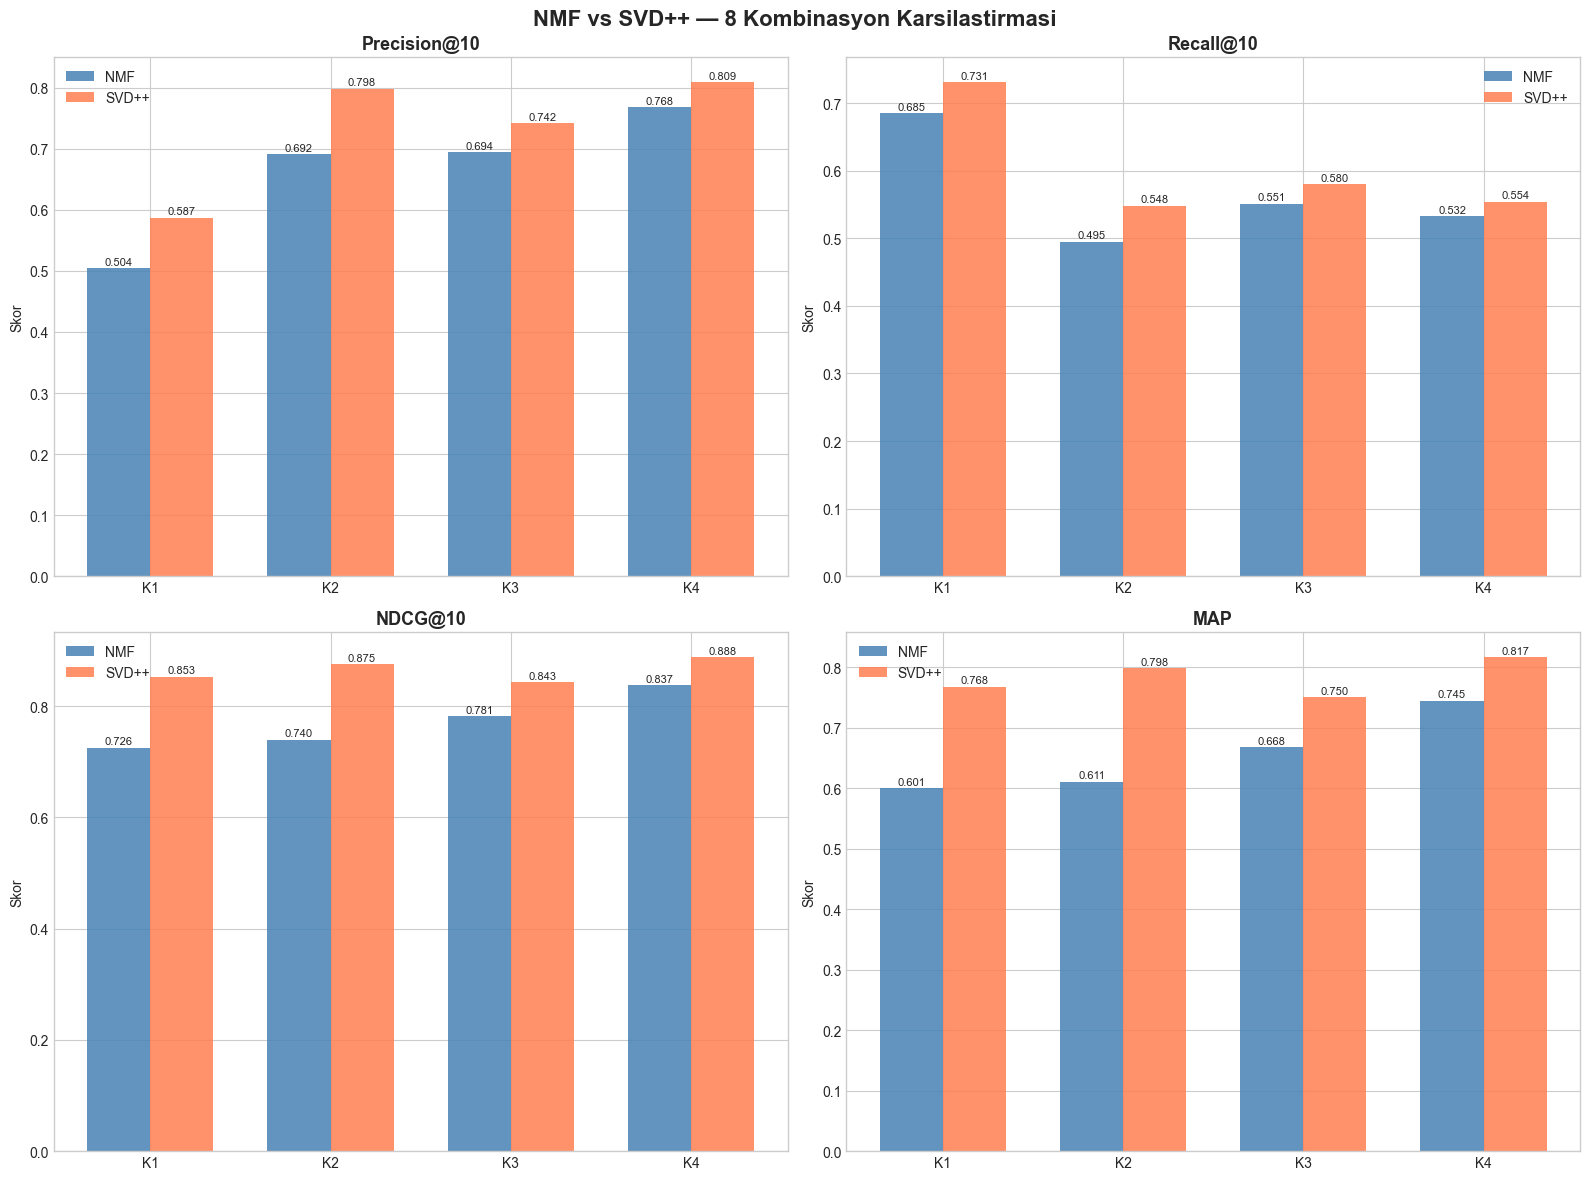

✅ Grafik kaydedildi!


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('NMF vs SVD++ — 8 Kombinasyon Karsilastirmasi', fontsize=16, fontweight='bold')

metrics    = ['Precision@10', 'Recall@10', 'NDCG@10', 'MAP']
nmf_color  = 'steelblue'
svdpp_color= 'coral'

for ax, metric in zip(axes.flatten(), metrics):
    nmf_vals   = results_df[results_df['Algoritma']=='NMF'][metric]
    svdpp_vals = results_df[results_df['Algoritma']=='SVD++'][metric]

    x     = np.arange(4)
    width = 0.35
    bars1 = ax.bar(x - width/2, nmf_vals.values,   width, label='NMF',   color=nmf_color,   alpha=0.85)
    bars2 = ax.bar(x + width/2, svdpp_vals.values, width, label='SVD++', color=svdpp_color, alpha=0.85)
    ax.set_title(metric, fontsize=13, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(['K1','K2','K3','K4'])
    ax.legend()
    ax.set_ylabel('Skor')
    for bar in bars1:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)
    for bar in bars2:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(r'C:\Users\Huseyin\Desktop\Movie_Lens\8_kombinasyon_karsilastirma.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('✅ Grafik kaydedildi!')

## 🎯 Bölüm 10 — En İyi Kombinasyon için Örnek Öneriler
> Hit?, Tahmin Doğru?, Fark kolonları ile 5 kullanıcı

In [21]:
# En iyi kombinasyonu yeniden calistir (preds ve recs elde etmek icin)
print(f'En iyi kombinasyon: {best_label}')
print(f'Algoritma: {best_row["Algoritma"]}')
print('\nModel yeniden egitiliyor...')

best_threshold = best_row['threshold']
best_min_user  = int(best_row['min_user'])

if best_row['Algoritma'] == 'NMF':
    # En iyi NMF kombinasyonunun parametrelerini bul
    best_combo = next(c for c in nmf_combinations if c['label'] == best_label)
    best_algo  = NMF(n_factors=best_combo['n_factors'], n_epochs=best_combo['n_epochs'],
                     random_state=42, verbose=False)
else:
    best_combo = next(c for c in svdpp_combinations if c['label'] == best_label)
    best_algo  = SVDpp(n_factors=best_combo['n_factors'], n_epochs=best_combo['n_epochs'],
                       lr_all=0.005, reg_all=0.02, random_state=42, verbose=False)

_, best_preds, best_recs, best_gt, best_testset = run_experiment(
    ratings, best_algo, best_row['Algoritma'], best_label,
    min_movie_ratings=50,
    min_user_ratings=best_min_user,
    threshold=best_threshold
)
print('✅ Model hazir!')

En iyi kombinasyon: SVD++-K4
Algoritma: SVD++

Model yeniden egitiliyor...
✅ Model hazir!


In [22]:
# 5 kullanici icin oneri tablosu
ornek_users = random.sample(list(best_gt.keys()), 5)

for user_id in ornek_users:
    print(f"\n{'='*70}")
    print(f"Kullanici: {user_id} | Algoritma: {best_label}")
    print(f"{'='*70}")

    user_test = {iid: true_r for uid, iid, true_r in best_testset if uid == user_id}
    recs      = best_recs.get(user_id, [])[:10]

    rows = []
    for movie_id in recs:
        gercek   = user_test.get(movie_id, None)
        tahmin   = next((est for uid, iid, _, est, _ in best_preds
                        if uid == user_id and iid == movie_id), None)
        film_adi = movies[movies['movieId']==movie_id]['title'].values
        film_adi = film_adi[0][:35] if len(film_adi) > 0 else str(movie_id)
        fark     = round(abs(tahmin - gercek), 2) if gercek and tahmin else '-'
        rows.append({
            'Film'           : film_adi,
            'Tahmin'         : round(tahmin, 2) if tahmin else '-',
            'Gercek'         : gercek if gercek else '-',
            'Hit?'           : '✅' if gercek and gercek >= best_threshold else '❌',
            'Tahmin Dogru?'  : '✅' if gercek and tahmin and abs(tahmin-gercek) < 1 else '❌',
            'Fark'           : fark
        })
    display(pd.DataFrame(rows))


Kullanici: 53810 | Algoritma: SVD++-K4


,Film,Tahmin,Gercek,Hit?,Tahmin Dogru?,Fark
0,Grand Day Out with Wallace and Grom,4.38,5.0,✅,✅,0.62
1,Young Frankenstein (1974),3.98,3.0,❌,✅,0.98
2,Ben-Hur (1959),3.79,4.0,✅,✅,0.21
3,Forrest Gump (1994),3.76,3.0,❌,✅,0.76
4,"Fish Called Wanda, A (1988)",3.74,4.0,✅,✅,0.26
5,"Nightmare Before Christmas, The (19",3.74,4.0,✅,✅,0.26
6,"Madness of King George, The (1994)",3.63,3.0,❌,✅,0.63
7,When Harry Met Sally... (1989),3.55,3.0,❌,✅,0.55
8,Rumble in the Bronx (Hont faan kui),3.29,4.0,✅,✅,0.71
9,Star Trek IV: The Voyage Home (1986,3.28,3.0,❌,✅,0.28



Kullanici: 45839 | Algoritma: SVD++-K4


,Film,Tahmin,Gercek,Hit?,Tahmin Dogru?,Fark
0,Wallace & Gromit: The Wrong Trouser,4.71,5.0,✅,✅,0.29
1,Dr. Strangelove or: How I Learned t,4.67,5.0,✅,✅,0.33
2,Yojimbo (1961),4.55,5.0,✅,✅,0.45
3,This Is Spinal Tap (1984),4.52,5.0,✅,✅,0.48
4,Amadeus (1984),4.28,5.0,✅,✅,0.72
5,"Great Dictator, The (1940)",4.27,3.0,❌,❌,1.27
6,"Great Day in Harlem, A (1994)",4.22,5.0,✅,✅,0.78
7,Cinema Paradiso (Nuovo cinema Parad,4.17,5.0,✅,✅,0.83
8,Henry V (1989),4.06,3.0,❌,❌,1.06
9,Ghostbusters (a.k.a. Ghost Busters),4.02,3.0,❌,❌,1.02



Kullanici: 86974 | Algoritma: SVD++-K4


,Film,Tahmin,Gercek,Hit?,Tahmin Dogru?,Fark
0,"Shawshank Redemption, The (1994)",4.64,4.0,✅,✅,0.64
1,Seven (a.k.a. Se7en) (1995),4.38,5.0,✅,✅,0.62
2,What's Eating Gilbert Grape (1993),4.12,4.0,✅,✅,0.12
3,Forrest Gump (1994),3.88,4.0,✅,✅,0.12
4,Tombstone (1993),3.73,5.0,✅,❌,1.27
5,Rob Roy (1995),3.68,4.0,✅,✅,0.32
6,Batman (1989),3.42,3.0,❌,✅,0.42
7,Crimson Tide (1995),3.36,3.0,❌,✅,0.36
8,Billy Madison (1995),3.29,4.0,✅,✅,0.71
9,Desperado (1995),3.29,4.0,✅,✅,0.71



Kullanici: 7436 | Algoritma: SVD++-K4


,Film,Tahmin,Gercek,Hit?,Tahmin Dogru?,Fark
0,"Maltese Falcon, The (1941)",4.69,5.0,✅,✅,0.31
1,10 Things I Hate About You (1999),4.69,4.0,✅,✅,0.69
2,One Flew Over the Cuckoo's Nest (19,4.68,5.0,✅,✅,0.32
3,Erin Brockovich (2000),4.62,5.0,✅,✅,0.38
4,Clerks (1994),4.60,4.0,✅,✅,0.60
5,"South Park: Bigger, Longer and Uncu",4.34,3.0,❌,❌,1.34
6,"Parent Trap, The (1961)",4.34,5.0,✅,✅,0.66
7,Who Framed Roger Rabbit? (1988),4.29,4.0,✅,✅,0.29
8,"Patriot, The (2000)",4.24,4.0,✅,✅,0.24
9,28 Days (2000),4.06,4.0,✅,✅,0.06



Kullanici: 37503 | Algoritma: SVD++-K4


,Film,Tahmin,Gercek,Hit?,Tahmin Dogru?,Fark
0,"Sting, The (1973)",4.44,5.0,✅,✅,0.56
1,"Good, the Bad and the Ugly, The (Bu",4.22,4.0,✅,✅,0.22
2,"Right Stuff, The (1983)",4.17,4.0,✅,✅,0.17
3,"Maltese Falcon, The (1941)",4.14,3.0,❌,❌,1.14
4,Three Days of the Condor (3 Days of,4.11,4.0,✅,✅,0.11
5,Serpico (1973),4.02,4.0,✅,✅,0.02
6,For a Few Dollars More (Per qualche,4.01,4.0,✅,✅,0.01
7,Rocky (1976),3.98,4.0,✅,✅,0.02
8,Midnight Express (1978),3.97,4.0,✅,✅,0.03
9,Predator (1987),3.90,4.0,✅,✅,0.10


In [23]:
from collections import defaultdict

# Ground truth olustur
gt_check = defaultdict(list)
for uid, iid, true_r in best_testset:
    if true_r >= best_threshold:
        gt_check[uid].append(iid)

# Metrikleri hesapla
metrics_check = compute_metrics(best_recs, gt_check, k=10)

print('En iyi kombinasyon icin metrikler:')
for k, v in metrics_check.items():
    print(f'  {k}: {v}')

print(f'\nOnceki sonuc (all_results icinden):')
prev = results_df.loc['SVD++-K4']
print(f'  Precision@10 : {prev["Precision@10"]}')
print(f'  Recall@10    : {prev["Recall@10"]}')
print(f'  NDCG@10      : {prev["NDCG@10"]}')
print(f'  MAP          : {prev["MAP"]}')

En iyi kombinasyon icin metrikler:
  Precision@10: 0.809
  Recall@10: 0.5543
  NDCG@10: 0.888
  MAP: 0.8169
  N_users: 85181

Onceki sonuc (all_results icinden):
  Precision@10 : 0.809
  Recall@10    : 0.5543
  NDCG@10      : 0.888
  MAP          : 0.8169


In [25]:
import json

als_results = [
    {"label": "ALS-K1", "rank": 10,  "maxIter": 5,  "threshold": 4.0, "min_user": 20, "Precision@10": 0.5881, "Recall@10": 0.7330, "NDCG@10": 0.8602, "MAP": 0.7780, "N_users": 135518},
    {"label": "ALS-K2", "rank": 10,  "maxIter": 5,  "threshold": 3.5, "min_user": 50, "Precision@10": 0.7998, "Recall@10": 0.5501, "NDCG@10": 0.8786, "MAP": 0.8032, "N_users": 85181},
    {"label": "ALS-K3", "rank": 50,  "maxIter": 10, "threshold": 4.0, "min_user": 50, "Precision@10": 0.7356, "Recall@10": 0.5768, "NDCG@10": 0.8380, "MAP": 0.7433, "N_users": 85115},
    {"label": "ALS-K4", "rank": 50,  "maxIter": 10, "threshold": 3.5, "min_user": 50, "Precision@10": 0.8042, "Recall@10": 0.5526, "NDCG@10": 0.8843, "MAP": 0.8115, "N_users": 85181},
]

# JSON olarak kaydet
with open(r'C:\Users\Huseyin\Desktop\Movie_Lens\spark\als_results.json', 'w') as f:
    json.dump(als_results, f, indent=2)

print('✅ ALS sonuçları kaydedildi!')
print(json.dumps(als_results, indent=2))

✅ ALS sonuçları kaydedildi!
[
  {
    "label": "ALS-K1",
    "rank": 10,
    "maxIter": 5,
    "threshold": 4.0,
    "min_user": 20,
    "Precision@10": 0.5881,
    "Recall@10": 0.733,
    "NDCG@10": 0.8602,
    "MAP": 0.778,
    "N_users": 135518
  },
  {
    "label": "ALS-K2",
    "rank": 10,
    "maxIter": 5,
    "threshold": 3.5,
    "min_user": 50,
    "Precision@10": 0.7998,
    "Recall@10": 0.5501,
    "NDCG@10": 0.8786,
    "MAP": 0.8032,
    "N_users": 85181
  },
  {
    "label": "ALS-K3",
    "rank": 50,
    "maxIter": 10,
    "threshold": 4.0,
    "min_user": 50,
    "Precision@10": 0.7356,
    "Recall@10": 0.5768,
    "NDCG@10": 0.838,
    "MAP": 0.7433,
    "N_users": 85115
  },
  {
    "label": "ALS-K4",
    "rank": 50,
    "maxIter": 10,
    "threshold": 3.5,
    "min_user": 50,
    "Precision@10": 0.8042,
    "Recall@10": 0.5526,
    "NDCG@10": 0.8843,
    "MAP": 0.8115,
    "N_users": 85181
  }
]


In [29]:
import pickle

# algo = son çalışan model = SVD++-K4
with open(r'C:\Users\Huseyin\Desktop\Movie_Lens\svdpp_best_model.pkl', 'wb') as f:
    pickle.dump(algo, f)

print(f'✅ Model kaydedildi!')
print(f'Tip: {type(algo)}')

✅ Model kaydedildi!
Tip: <class 'surprise.prediction_algorithms.matrix_factorization.SVDpp'>


In [34]:
import time

# ratings'den popüler filmleri al
popular_movies = ratings.groupby('movieId')['rating'].count()
popular_1000   = popular_movies.nlargest(1000).index.tolist()

# Kullanıcı 37503'ün izledikleri
user_id     = 37503
izledikleri = set(ratings[ratings['userId'] == user_id]['movieId'])

# Hiç izlemediği popüler filmler
izlemedikleri = [m for m in popular_1000 if m not in izledikleri]
print(f'Tahmin yapılacak film sayısı: {len(izlemedikleri)}')

# Hız testi
start = time.time()
tahminler = []
for movie_id in izlemedikleri:
    pred = algo.predict(user_id, movie_id)
    tahminler.append((movie_id, pred.est))
sure = time.time() - start

print(f'Süre: {sure:.2f}s')

# Top-10
tahminler.sort(key=lambda x: x[1], reverse=True)
print('\nTop-10 Öneri:')
for movie_id, skor in tahminler[:10]:
    film_adi = movies[movies['movieId']==movie_id]['title'].values[0]
    print(f'  {film_adi}: {skor:.2f}')

Tahmin yapılacak film sayısı: 820
Süre: 0.16s

Top-10 Öneri:
  Schindler's List (1993): 4.48
  12 Angry Men (1957): 4.47
  Saving Private Ryan (1998): 4.42
  To Kill a Mockingbird (1962): 4.37
  Boot, Das (Boat, The) (1981): 4.36
  Bridge on the River Kwai, The (1957): 4.34
  Godfather, The (1972): 4.34
  Usual Suspects, The (1995): 4.31
  Casablanca (1942): 4.29
  Braveheart (1995): 4.27


In [35]:
import time

# Tüm filmler
tum_filmler = ratings['movieId'].unique().tolist()

# Kullanıcı 37503'ün izledikleri
user_id     = 37503
izledikleri = set(ratings[ratings['userId'] == user_id]['movieId'])

# Hiç izlemediği tüm filmler
izlemedikleri = [m for m in tum_filmler if m not in izledikleri]
print(f'Tahmin yapılacak film sayısı: {len(izlemedikleri)}')

# Hız testi
start = time.time()
tahminler = []
for movie_id in izlemedikleri:
    pred = algo.predict(user_id, movie_id)
    tahminler.append((movie_id, pred.est))
sure = time.time() - start

print(f'Süre: {sure:.2f}s')

# Top-10
tahminler.sort(key=lambda x: x[1], reverse=True)
print('\nTop-10 Öneri:')
for movie_id, skor in tahminler[:10]:
    film_adi = movies[movies['movieId']==movie_id]['title'].values[0]
    print(f'  {film_adi}: {skor:.2f}')

Tahmin yapılacak film sayısı: 26457
Süre: 1.80s

Top-10 Öneri:
  Civil War, The (1990): 4.69
  Band of Brothers (2001): 4.58
  Schindler's List (1993): 4.48
  12 Angry Men (1957): 4.47
  Saving Private Ryan (1998): 4.42
  To Kill a Mockingbird (1962): 4.37
  Boot, Das (Boat, The) (1981): 4.36
  Bridge on the River Kwai, The (1957): 4.34
  Godfather, The (1972): 4.34
  Fawlty Towers (1975-1979): 4.32


In [36]:
import time

user_id = 37503

# Bu kullanıcının test setindeki filmleri
test_movies = [iid for uid, iid, _ in best_testset if uid == user_id]
print(f'Test setindeki film sayısı: {len(test_movies)}')

# Hız testi
start = time.time()
tahminler = []
for movie_id in test_movies:
    pred = algo.predict(user_id, movie_id)
    tahminler.append((movie_id, pred.est))
sure = time.time() - start

print(f'Süre: {sure:.2f}s')

# Top-10
tahminler.sort(key=lambda x: x[1], reverse=True)
print('\nTop-10 Öneri:')
for movie_id, skor in tahminler[:10]:
    film_adi = movies[movies['movieId']==movie_id]['title'].values[0]
    print(f'  {film_adi}: {skor:.2f}')

Test setindeki film sayısı: 57
Süre: 0.02s

Top-10 Öneri:
  Sting, The (1973): 4.44
  Good, the Bad and the Ugly, The (Buono, il brutto, il cattivo, Il) (1966): 4.22
  Right Stuff, The (1983): 4.17
  Maltese Falcon, The (1941): 4.14
  Three Days of the Condor (3 Days of the Condor) (1975): 4.11
  Serpico (1973): 4.02
  For a Few Dollars More (Per qualche dollaro in più) (1965): 4.01
  Rocky (1976): 3.98
  Midnight Express (1978): 3.97
  Predator (1987): 3.90


In [37]:
user_counts = ratings.groupby('userId')['rating'].count()

print('Kullanıcı dağılımı:')
print(f'  Toplam kullanıcı        : {len(user_counts):,}')
print(f'  >= 50 rating            : {(user_counts >= 50).sum():,}')
print(f'  >= 100 rating           : {(user_counts >= 100).sum():,}')
print(f'  >= 150 rating           : {(user_counts >= 150).sum():,}')
print(f'  >= 200 rating           : {(user_counts >= 200).sum():,}')
print(f'  >= 500 rating           : {(user_counts >= 500).sum():,}')

print(f'\nOrtalama rating sayisi  : {user_counts.mean():.1f}')
print(f'Medyan rating sayisi    : {user_counts.median():.1f}')

Kullanıcı dağılımı:
  Toplam kullanıcı        : 138,493
  >= 50 rating            : 85,307
  >= 100 rating           : 52,596
  >= 150 rating           : 35,817
  >= 200 rating           : 26,826
  >= 500 rating           : 7,491

Ortalama rating sayisi  : 144.4
Medyan rating sayisi    : 68.0


In [38]:
# min_user=100 ile SVD++-K4 parametreleri
print('SVD++ min_user=100 egitiliyor...')
start_total = time.time()

# Veri hazirla
trainset_100, testset_100 = prepare_data(
    ratings,
    min_movie_ratings=50,
    min_user_ratings=100
)

# Ground truth
THRESHOLD_100 = 3.5
ground_truth_100 = defaultdict(list)
for uid, iid, true_r in testset_100:
    if true_r >= THRESHOLD_100:
        ground_truth_100[uid].append(iid)

print(f'Test kullanici sayisi: {len(ground_truth_100):,}')

# Model egit
svdpp_100 = SVDpp(
    n_factors=50, n_epochs=20,
    lr_all=0.005, reg_all=0.02,
    random_state=42, verbose=False
)
svdpp_100.fit(trainset_100)

# Tahmin
preds_100 = svdpp_100.test(testset_100)
recs_100  = get_top_k_recommendations(preds_100, 10)
metrics_100 = compute_metrics(recs_100, ground_truth_100, 10)

print(f'\nSVD++-K4 (min_user=100) SONUCLARI:')
print(f'  Egitim suresi : {time.time()-start_total:.1f}s')
for k, v in metrics_100.items():
    print(f'  {k}: {v}')

print(f'\nKarsilastirma:')
print(f'  {"Metrik":<15} {"min_user=50":<15} {"min_user=100":<15}')
print(f'  {"-"*45}')
prev = results_df.loc["SVD++-K4"]
for m in ["Precision@10", "Recall@10", "NDCG@10", "MAP"]:
    print(f'  {m:<15} {prev[m]:<15} {metrics_100[m]:<15}')

SVD++ min_user=100 egitiliyor...
Test kullanici sayisi: 52,576

SVD++-K4 (min_user=100) SONUCLARI:
  Egitim suresi : 24367.3s
  Precision@10: 0.8659
  Recall@10: 0.3653
  NDCG@10: 0.8902
  MAP: 0.8257
  N_users: 52576

Karsilastirma:
  Metrik          min_user=50     min_user=100   
  ---------------------------------------------
  Precision@10    0.809           0.8659         
  Recall@10       0.5543          0.3653         
  NDCG@10         0.888           0.8902         
  MAP             0.8169          0.8257         


In [39]:
# Orijinal
toplam_rating = len(ratings)

# min_user=50 filtresi
active_50 = ratings.groupby('userId')['rating'].count()
active_50 = active_50[active_50 >= 50].index
filtered_50 = ratings[
    ratings['movieId'].isin(popular_movies) &
    ratings['userId'].isin(active_50)
]

# min_user=100 filtresi
active_100 = ratings.groupby('userId')['rating'].count()
active_100 = active_100[active_100 >= 100].index
filtered_100 = ratings[
    ratings['movieId'].isin(popular_movies) &
    ratings['userId'].isin(active_100)
]

print(f'Orijinal veri        : {toplam_rating:,}')
print(f'min_user=50 sonrası  : {len(filtered_50):,} ({len(filtered_50)/toplam_rating*100:.1f}%)')
print(f'min_user=100 sonrası : {len(filtered_100):,} ({len(filtered_100)/toplam_rating*100:.1f}%)')
print(f'\nmin_user=50  → {toplam_rating - len(filtered_50):,} rating düştü')
print(f'min_user=100 → {toplam_rating - len(filtered_100):,} rating düştü')

Orijinal veri        : 20,000,263
min_user=50 sonrası  : 9,261,878 (46.3%)
min_user=100 sonrası : 7,792,640 (39.0%)

min_user=50  → 10,738,385 rating düştü
min_user=100 → 12,207,623 rating düştü


In [41]:
import gc

# Artık ihtiyaç olmayan büyük değişkenleri sil
del filtered_50
del filtered_100
del active_50
del active_100
gc.collect()

print('✅ Bellek temizlendi!')

# Şimdi kaydet
import pickle
with open(r'C:\Users\Huseyin\Desktop\Movie_Lens\svdpp_best_model_100.pkl', 'wb') as f:
    pickle.dump(svdpp_100, f)

print('✅ Model kaydedildi!')

✅ Bellek temizlendi!
✅ Model kaydedildi!


In [42]:
import random

# svdpp_100 modelini kullan
# Test setinden 5 kullanıcı seç
gt_users_100 = list(ground_truth_100.keys())
ornek_users_100 = random.sample(gt_users_100, 5)

# Test setini dict'e çevir
test_dict_100 = {}
for uid, iid, true_r in testset_100:
    test_dict_100[(uid, iid)] = true_r

for user_id in ornek_users_100:
    print(f"\n{'='*70}")
    print(f"Kullanici: {user_id} | SVD++-K4 (min_user=100)")
    print(f"{'='*70}")

    # Bu kullanıcının test filmleri
    user_test = {iid: r for (uid, iid), r in test_dict_100.items() if uid == user_id}

    # Top-10 öneri
    recs = recs_100.get(user_id, [])[:10]

    rows = []
    for movie_id in recs:
        gercek   = user_test.get(movie_id, None)
        tahmin   = next((est for uid, iid, _, est, _ in preds_100
                        if uid == user_id and iid == movie_id), None)
        film_adi = movies[movies['movieId']==movie_id]['title'].values
        film_adi = film_adi[0][:35] if len(film_adi) > 0 else str(movie_id)
        fark     = round(abs(tahmin - gercek), 2) if gercek and tahmin else '-'
        rows.append({
            'Film'          : film_adi,
            'Tahmin'        : round(tahmin, 2) if tahmin else '-',
            'Gercek'        : gercek if gercek else '-',
            'Hit?'          : '✅' if gercek and gercek >= 3.5 else '❌',
            'Tahmin Dogru?' : '✅' if gercek and tahmin and abs(tahmin-gercek) < 1 else '❌',
            'Fark'          : fark
        })
    display(pd.DataFrame(rows))


Kullanici: 133254 | SVD++-K4 (min_user=100)


,Film,Tahmin,Gercek,Hit?,Tahmin Dogru?,Fark
0,"Silence of the Lambs, The (1991)",4.55,5.0,✅,✅,0.45
1,Gone with the Wind (1939),4.32,5.0,✅,✅,0.68
2,"Sixth Sense, The (1999)",4.30,3.0,❌,❌,1.30
3,Raiders of the Lost Ark (Indiana Jo,4.05,4.0,✅,✅,0.05
4,Blue Velvet (1986),3.97,3.0,❌,✅,0.97
5,Boogie Nights (1997),3.89,5.0,✅,❌,1.11
6,"Matrix, The (1999)",3.89,2.0,❌,❌,1.89
7,Annie Hall (1977),3.86,4.0,✅,✅,0.14
8,Fight Club (1999),3.79,1.0,❌,❌,2.79
9,Broadcast News (1987),3.74,5.0,✅,❌,1.26



Kullanici: 2117 | SVD++-K4 (min_user=100)


,Film,Tahmin,Gercek,Hit?,Tahmin Dogru?,Fark
0,"Usual Suspects, The (1995)",4.42,5.0,✅,✅,0.58
1,Wallace & Gromit: The Wrong Trouser,4.34,5.0,✅,✅,0.66
2,"Piano, The (1993)",4.15,3.0,❌,❌,1.15
3,Fantasia (1940),3.99,5.0,✅,❌,1.01
4,"Crouching Tiger, Hidden Dragon (Wo",3.86,4.0,✅,✅,0.14
5,"Full Monty, The (1997)",3.85,4.0,✅,✅,0.15
6,Traffic (2000),3.68,2.0,❌,❌,1.68
7,Pay It Forward (2000),3.64,4.0,✅,✅,0.36
8,Magnolia (1999),3.62,2.0,❌,❌,1.62
9,Unforgiven (1992),3.58,5.0,✅,❌,1.42



Kullanici: 95309 | SVD++-K4 (min_user=100)


,Film,Tahmin,Gercek,Hit?,Tahmin Dogru?,Fark
0,Three Colors: Blue (Trois couleurs:,4.55,5.0,✅,✅,0.45
1,Amelie (Fabuleux destin d'Amélie Po,4.53,4.5,✅,✅,0.03
2,Three Colors: White (Trzy kolory: B,4.50,5.0,✅,✅,0.50
3,Life Is Beautiful (La Vita è bella),4.40,4.5,✅,✅,0.10
4,Eternal Sunshine of the Spotless Mi,4.39,3.5,✅,✅,0.89
5,Chicago (2002),4.22,3.5,✅,✅,0.72
6,Show Me Love (Fucking Åmål) (1998),4.21,4.0,✅,✅,0.21
7,Love Actually (2003),4.17,5.0,✅,✅,0.83
8,Garden State (2004),4.11,4.0,✅,✅,0.11
9,Monty Python's Life of Brian (1979),4.00,5.0,✅,❌,1.00



Kullanici: 44230 | SVD++-K4 (min_user=100)


,Film,Tahmin,Gercek,Hit?,Tahmin Dogru?,Fark
0,Seven Samurai (Shichinin no samurai,4.03,5.0,✅,✅,0.97
1,"Avengers, The (2012)",3.98,4.5,✅,✅,0.52
2,Star Trek (2009),3.96,4.0,✅,✅,0.04
3,Memento (2000),3.93,4.0,✅,✅,0.07
4,"Great Escape, The (1963)",3.86,3.5,✅,✅,0.36
5,Finding Nemo (2003),3.86,4.0,✅,✅,0.14
6,How to Train Your Dragon 2 (2014),3.81,4.0,✅,✅,0.19
7,Source Code (2011),3.79,3.5,✅,✅,0.29
8,Catch Me If You Can (2002),3.75,4.0,✅,✅,0.25
9,X-Men: First Class (2011),3.74,3.5,✅,✅,0.24



Kullanici: 61370 | SVD++-K4 (min_user=100)


,Film,Tahmin,Gercek,Hit?,Tahmin Dogru?,Fark
0,Trust (1990),5.00,5.0,✅,✅,0.00
1,Hear My Song (1991),4.75,5.0,✅,✅,0.25
2,Paris Is Burning (1990),4.57,5.0,✅,✅,0.43
3,Murder in the First (1995),4.45,5.0,✅,✅,0.55
4,Seven (a.k.a. Se7en) (1995),4.44,5.0,✅,✅,0.56
5,Stonewall (1995),4.43,5.0,✅,✅,0.57
6,Circle of Friends (1995),4.36,5.0,✅,✅,0.64
7,"House of the Spirits, The (1993)",4.30,5.0,✅,✅,0.70
8,Captives (1994),4.24,5.0,✅,✅,0.76
9,Little Odessa (1994),4.21,5.0,✅,✅,0.79


In [44]:
import pickle

# Kaydedilen modeli yükle
with open(r'C:\Users\Huseyin\Desktop\Movie_Lens\svdpp_best_model_100.pkl', 'rb') as f:
    loaded_model_100 = pickle.load(f)

print('✅ Model yüklendi!')

# 44230 kullanıcısının test setindeki filmleri
user_id = 44230

user_test = {iid: true_r for uid, iid, true_r in testset_100 if uid == user_id}
print(f'Kullanici {user_id} test setindeki film sayisi: {len(user_test)}')

# Tahmin yap
rows = []
for movie_id, gercek in user_test.items():
    tahmin   = loaded_model_100.predict(user_id, movie_id).est
    film_adi = movies[movies['movieId']==movie_id]['title'].values
    film_adi = film_adi[0][:35] if len(film_adi) > 0 else str(movie_id)
    fark     = round(abs(tahmin - gercek), 2)
    rows.append({
        'Film'          : film_adi,
        'Tahmin'        : round(tahmin, 2),
        'Gercek'        : gercek,
        'Hit?'          : '✅' if gercek >= 3.5 else '❌',
        'Tahmin Dogru?' : '✅' if abs(tahmin - gercek) < 1 else '❌',
        'Fark'          : fark
    })

# Tahmine göre sırala, Top-10 göster
df_44230 = pd.DataFrame(rows).sort_values('Tahmin', ascending=False)
print(f'\nKullanici {user_id} - Top-10 Oneri (Kaydedilen Model):')
display(df_44230.head(10))

✅ Model yüklendi!
Kullanici 44230 test setindeki film sayisi: 26

Kullanici 44230 - Top-10 Oneri (Kaydedilen Model):


,Film,Tahmin,Gercek,Hit?,Tahmin Dogru?,Fark
16,Seven Samurai (Shichinin no samurai,4.03,5.0,✅,✅,0.97
10,"Avengers, The (2012)",3.98,4.5,✅,✅,0.52
13,Star Trek (2009),3.96,4.0,✅,✅,0.04
8,Memento (2000),3.93,4.0,✅,✅,0.07
24,"Great Escape, The (1963)",3.86,3.5,✅,✅,0.36
23,Finding Nemo (2003),3.86,4.0,✅,✅,0.14
0,How to Train Your Dragon 2 (2014),3.81,4.0,✅,✅,0.19
1,Source Code (2011),3.79,3.5,✅,✅,0.29
4,Catch Me If You Can (2002),3.75,4.0,✅,✅,0.25
11,X-Men: First Class (2011),3.74,3.5,✅,✅,0.24
